# Dummy Directed Graph: Baseline vs Rigid Zone-Completion

Self-contained demo on **synthetic data**. Numbers mean nothing. Purpose: preview the diagram and animation before running on real Amazon data.

Sections: 1 Dummy Data · 2 Routes and Metrics · 3 Static Directed Graph · 4 Animated Directed Graph

## 1. Dummy Data
### Synthetic Stops, Zones and Travel-Time Matrix

In [1]:
# ==========================================================
# SYNTHETIC STOPS, ZONES AND TRAVEL-TIME MATRIX (DUMMY DATA)
# ==========================================================
# Defines the same names the real notebook uses: route_data, ROUTE_ID, env.
# To use REAL data: delete this cell, run the real notebook's setup, keep sections 2-4.
import types
import numpy as np

rng = np.random.default_rng(1)
N_STOPS = 80
ids = ["UZ"] + [f"S{i:03d}" for i in range(N_STOPS)]
zone_centers = {"A": (-118.34, 33.89), "B": (-118.32, 33.90),
                "C": (-118.30, 33.92), "D": (-118.35, 33.93)}
zone_names = list(zone_centers)

dummy_stops = {"UZ": {"lat": 33.9187, "lng": -118.3248}}        # station, no zone
for i, n in enumerate(ids[1:]):
    cx, cy = zone_centers[zone_names[i % 4]]
    dummy_stops[n] = {"lat": cy + rng.normal(0, 0.006), "lng": cx + rng.normal(0, 0.006),
                      "zone_id": zone_names[i % 4]}

P = np.array([[dummy_stops[n]["lng"], dummy_stops[n]["lat"]] for n in ids])
D = np.linalg.norm(P[:, None] - P[None], axis=2) * 1e5 * 0.5     # seconds, distance-based
D = D * (1 + rng.uniform(0, 0.2, D.shape))                       # asymmetric noise
np.fill_diagonal(D, 0)

env = types.SimpleNamespace(travel_time_matrix=D,
                            node_to_idx={n: i for i, n in enumerate(ids)},
                            node_ids=ids)
ROUTE_ID = "DUMMY_ROUTE"
route_data = {ROUTE_ID: {"stops": dummy_stops}}
print(f"Dummy data ready: {len(ids)} nodes, {len(zone_names)} zones, matrix {D.shape}")

Dummy data ready: 81 nodes, 4 zones, matrix (81, 81)


## 2. Routes and Metrics
### Build Baseline and Zone-Completion Routes

In [2]:
# ==========================================================
# BUILD BASELINE (NEAREST-NEIGHBOR) AND ZONE-COMPLETION ROUTES
# ==========================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import FancyArrowPatch
from IPython.display import Image, display

WH = "UZ"
stops = route_data[ROUTE_ID]["stops"]            # not `route`: overwritten in eval cell
M = env.travel_time_matrix
idx = env.node_to_idx
node_ids = list(env.node_ids)
N = len(node_ids)
zone = {n: stops[n].get("zone_id") for n in node_ids}   # station has no zone

def edge_t(a, b):
    t = float(M[int(idx[a]), int(idx[b])])
    return t if np.isfinite(t) else np.inf

def nearest(cands, cur):
    return min(cands, key=lambda n: edge_t(cur, n))

def nearest_neighbor_route(start):
    left = [n for n in node_ids if n != start]
    cur, r = start, [start]
    while left:
        nxt = nearest(left, cur); left.remove(nxt); r.append(nxt); cur = nxt
    return r

def zone_completion_route(start):
    """Rigid policy: never leave a zone until every stop in it is served."""
    deliveries = [n for n in node_ids if n != start]
    remaining = {}
    for n in deliveries:
        remaining.setdefault(zone[n], []).append(n)
    cur, r = start, [start]
    z = zone[nearest(deliveries, cur)]                   # start in zone of nearest stop
    while remaining:
        while remaining[z]:
            nxt = nearest(remaining[z], cur)
            remaining[z].remove(nxt); r.append(nxt); cur = nxt
        del remaining[z]
        if remaining:
            z = zone[nearest([n for zz in remaining for n in remaining[zz]], cur)]
    return r

BASE_NAME, RIGID_NAME = "Baseline (nearest-neighbor)", "Rigid zone-completion"
routes = {BASE_NAME: nearest_neighbor_route(WH), RIGID_NAME: zone_completion_route(WH)}

for name, r in routes.items():
    assert r[0] == WH and len(r) == N and len(set(r)) == N, name
    print(f"{name:30s} total {sum(edge_t(a, b) for a, b in zip(r[:-1], r[1:])) / 60:8.2f} min  valid")


Baseline (nearest-neighbor)    total   410.66 min  valid
Rigid zone-completion          total   431.14 min  valid


### Zone-Exit Timeline Metrics

In [3]:
# ==========================================================
# ZONE-EXIT TIMELINE METRICS
# ==========================================================
Z0 = zone[routes[BASE_NAME][1]]                          # start zone = zone of nearest stop
assert zone[routes[RIGID_NAME][1]] == Z0

def timeline(r):
    cum = np.concatenate([[0.0], np.cumsum([edge_t(a, b) for a, b in zip(r[:-1], r[1:])])])
    z0_pos = [i for i in range(1, len(r)) if zone[r[i]] == Z0]
    exit_i = next((i for i in range(2, len(r)) if zone[r[i]] != Z0), len(r))
    return dict(route=r, cum=cum, exit_i=exit_i, z0_pos=z0_pos,
                t_exit=cum[exit_i - 1] / 60,             # leaves last in-zone stop of first run
                t_clear=cum[max(z0_pos)] / 60,           # last start-zone stop served
                left_behind=len(z0_pos) - (exit_i - 1),
                total=cum[-1] / 60)

TL = {name: timeline(r) for name, r in routes.items()}
print(f"Start zone: {Z0} | stops in zone: {len(TL[BASE_NAME]['z0_pos'])}\n")
print(f"{'approach':30s} {'first exit':>10s} {'cleared':>9s} {'left behind':>12s} {'total':>8s}")
for name, t in TL.items():
    print(f"{name:30s} {t['t_exit']:9.1f}m {t['t_clear']:8.1f}m {t['left_behind']:12d} {t['total']:7.1f}m")


Start zone: B | stops in zone: 20

approach                       first exit   cleared  left behind    total
Baseline (nearest-neighbor)         57.4m    364.8m            3   410.7m
Rigid zone-completion               91.4m     91.4m            0   431.1m


## 3. Static Directed Graph
### Route Arrows, Start Area and Zone Exit

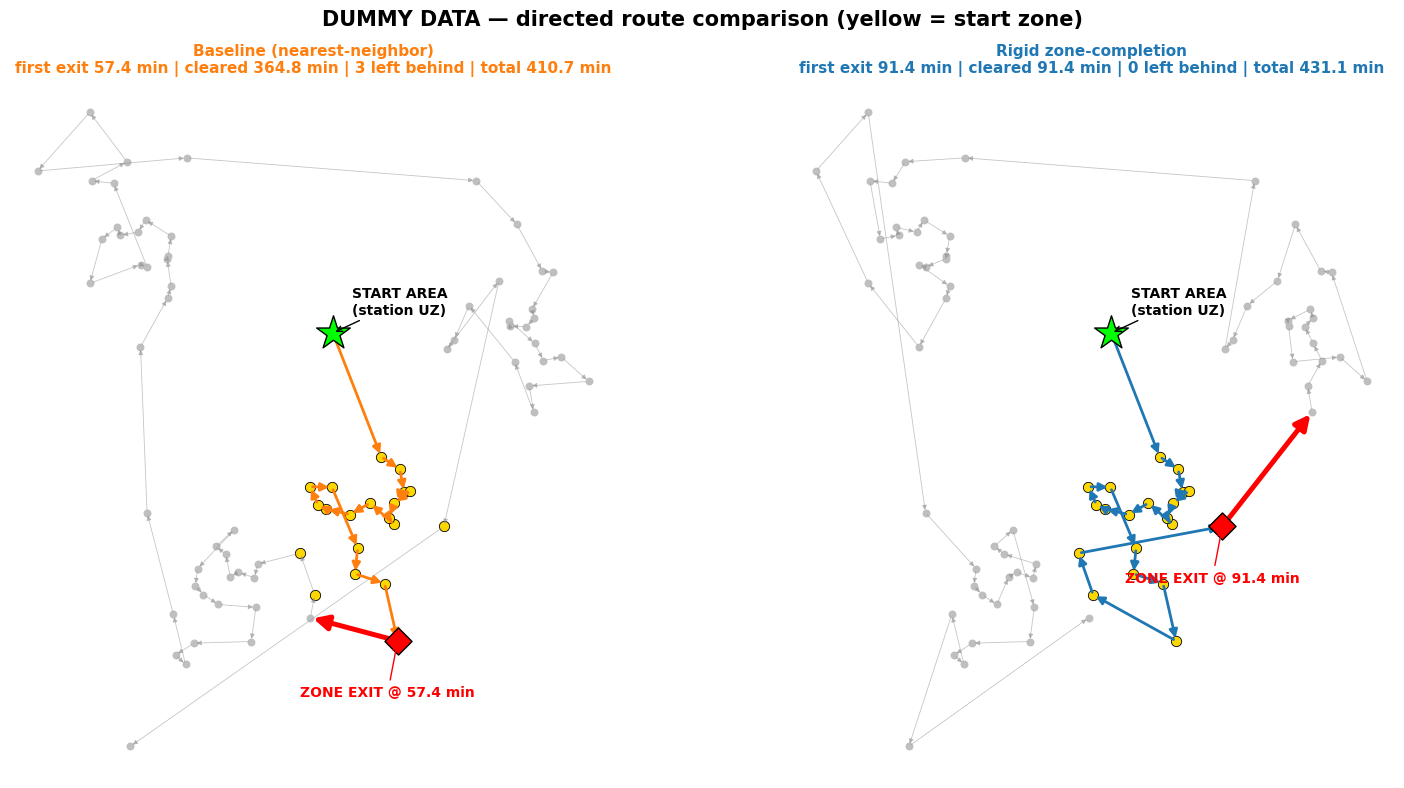

In [4]:
# ==========================================================
# STATIC DIRECTED GRAPH — START AREA + ZONE EXIT (DUMMY DATA)
# ==========================================================
pos = {n: (stops[n]["lng"], stops[n]["lat"]) for n in node_ids}
route_colors = {BASE_NAME: "tab:orange", RIGID_NAME: "tab:blue"}

fig, axs = plt.subplots(1, 2, figsize=(16, 8))
for ax, name in zip(axs, routes):
    r, m, col = routes[name], TL[name], route_colors[name]
    e = m["exit_i"]
    inz = [n for n in node_ids if n != WH and zone[n] == Z0]
    oth = [n for n in node_ids if n != WH and zone[n] != Z0]
    ax.scatter(*zip(*(pos[n] for n in oth)), s=22, c="0.75", zorder=2)
    ax.scatter(*zip(*(pos[n] for n in inz)), s=55, c="gold", edgecolors="k", linewidths=0.6, zorder=3)

    for k, (a, b) in enumerate(zip(r[:-1], r[1:])):
        if k < e - 1:      kw = dict(color=col, lw=2.0, mutation_scale=12, zorder=5)      # first-zone run
        elif k == e - 1:   kw = dict(color="red", lw=3.6, mutation_scale=22, zorder=6)    # zone-exit edge
        else:              kw = dict(color="0.55", lw=0.6, mutation_scale=7, alpha=0.5, zorder=4)
        ax.add_patch(FancyArrowPatch(pos[a], pos[b], arrowstyle="-|>", **kw))

    ax.scatter(*pos[WH], marker="*", s=650, c="lime", edgecolors="k", zorder=8)
    ax.annotate("START AREA\n(station UZ)", pos[WH], xytext=(14, 14), textcoords="offset points",
                fontweight="bold", arrowprops=dict(arrowstyle="->"), zorder=9)
    if e < len(r):
        ex = r[e - 1]
        ax.scatter(*pos[ex], marker="D", s=190, c="red", edgecolors="k", zorder=9)
        ax.annotate(f"ZONE EXIT @ {m['t_exit']:.1f} min", pos[ex], xytext=(-70, -40),
                    textcoords="offset points", color="red", fontweight="bold",
                    arrowprops=dict(arrowstyle="->", color="red"), zorder=9)
    ax.set_title(f"{name}\nfirst exit {m['t_exit']:.1f} min | cleared {m['t_clear']:.1f} min | "
                 f"{m['left_behind']} left behind | total {m['total']:.1f} min",
                 color=col, fontsize=11, fontweight="bold")
    ax.autoscale(); ax.set_aspect(1 / np.cos(np.radians(33.9))); ax.axis("off")

fig.suptitle("DUMMY DATA — directed route comparison (yellow = start zone)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Animated Directed Graph
### Vehicles Racing to Leave the Start Zone

Orange = baseline (nearest-neighbor). Blue = rigid zone-completion. Red arrow/diamond = zone exit. Green circle = zone fully cleared.

Saved: zone_exit_animation.gif


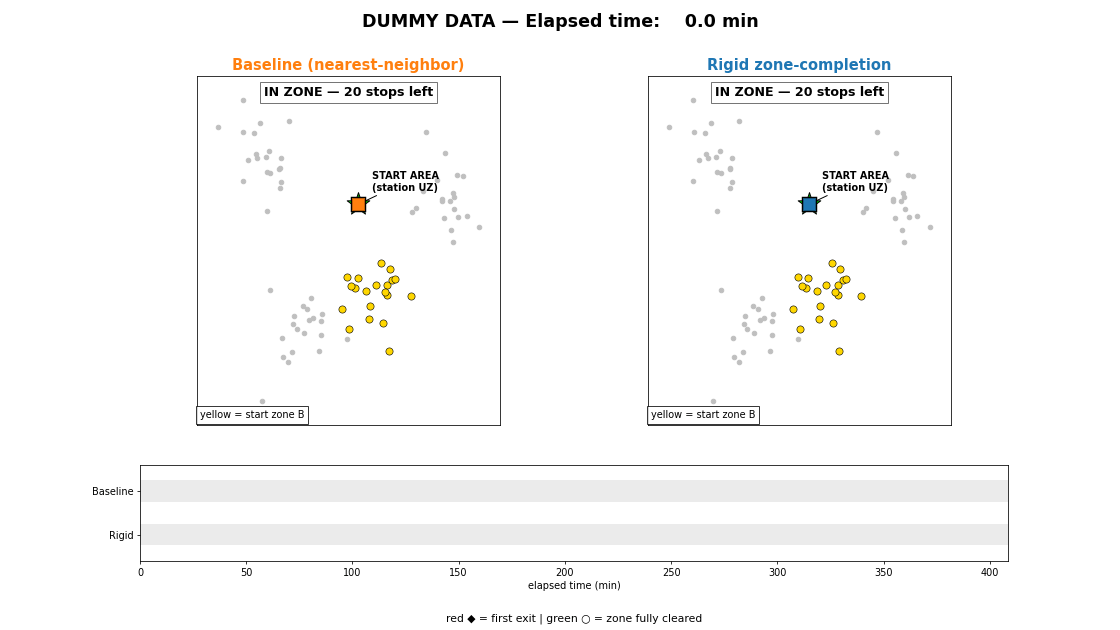

In [5]:
# ==========================================================
# ANIMATED DIRECTED GRAPH — VEHICLES RACE TO LEAVE START ZONE
# ==========================================================
COLORS = {BASE_NAME: "tab:orange", RIGID_NAME: "tab:blue"}
N_FRAMES, HOLD, FPS, DPI = 180, 25, 15, 70
GIF_PATH = "zone_exit_animation.gif"

pos = {n: (stops[n]["lng"], stops[n]["lat"]) for n in node_ids}
T_END = min(1.12 * max(t["t_clear"] for t in TL.values()),
            min(t["total"] for t in TL.values())) * 60    # seconds, same clock for both
ts = np.concatenate([np.linspace(0, T_END, N_FRAMES), np.full(HOLD, T_END)])

# nodes visible in either animation window -> zoom map to them
seen = set()
for t in TL.values():
    seen |= set(t["route"][: int(np.searchsorted(t["cum"], T_END)) + 2])
xs, ys = zip(*(pos[n] for n in seen))
padx, pady = 0.08 * (max(xs) - min(xs) + 1e-9), 0.08 * (max(ys) - min(ys) + 1e-9)
xlim, ylim = (min(xs) - padx, max(xs) + padx), (min(ys) - pady, max(ys) + pady)

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[4, 1.1], hspace=0.18, wspace=0.08)
axes = {BASE_NAME: fig.add_subplot(gs[0, 0]), RIGID_NAME: fig.add_subplot(gs[0, 1])}
axb = fig.add_subplot(gs[1, :])
clock = fig.suptitle("", fontsize=18, fontweight="bold")

panel = {}
for name, ax in axes.items():
    tl, col = TL[name], COLORS[name]
    r = tl["route"]
    inz = [n for n in node_ids if n != WH and zone[n] == Z0]
    out = [n for n in node_ids if n != WH and zone[n] != Z0 and n in seen]
    ax.scatter(*zip(*(pos[n] for n in out)), s=22, c="0.75", zorder=2)
    ax.scatter(*zip(*(pos[n] for n in inz)), s=55, c="gold", edgecolors="k", linewidths=0.6, zorder=3)
    ax.scatter(*pos[WH], marker="*", s=600, c="lime", edgecolors="k", zorder=6)
    ax.annotate("START AREA\n(station UZ)", pos[WH], xytext=(14, 14), textcoords="offset points",
                fontweight="bold", arrowprops=dict(arrowstyle="->"), zorder=7)
    ax.set_title(name, color=col, fontsize=15, fontweight="bold")
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect(1 / np.cos(np.radians(np.mean(ylim)))); ax.set_xticks([]); ax.set_yticks([])
    ax.text(0.01, 0.02, f"yellow = start zone {Z0}", transform=ax.transAxes, fontsize=10,
            bbox=dict(fc="white", alpha=0.8))

    arrows = []
    for k in range(min(int(np.searchsorted(tl["cum"], T_END)) + 1, len(r) - 1)):
        is_exit = (k == tl["exit_i"] - 1)
        p = FancyArrowPatch(pos[r[k]], pos[r[k + 1]], arrowstyle="-|>",
                            mutation_scale=22 if is_exit else 11, lw=3.5 if is_exit else 1.7,
                            color="red" if is_exit else col, alpha=0.9, zorder=4, visible=False)
        ax.add_patch(p); arrows.append(p)
    prog, = ax.plot([], [], color=col, lw=1.7, zorder=4)
    veh, = ax.plot([], [], "s", ms=15, mfc=col, mec="k", mew=1.5, zorder=8)
    exit_mk, = ax.plot([], [], "D", ms=15, mfc="red", mec="k", zorder=7)
    clear_mk, = ax.plot([], [], "o", ms=22, mfc="none", mec="green", mew=3.5, zorder=7)
    info = ax.text(0.5, 0.97, "", transform=ax.transAxes, ha="center", va="top",
                   fontsize=13, fontweight="bold", bbox=dict(fc="white", ec="0.4", alpha=0.92), zorder=10)
    banner = ax.text(0.5, 0.5, "", transform=ax.transAxes, ha="center", va="center",
                     fontsize=26, fontweight="bold", color="red", zorder=11,
                     bbox=dict(fc="white", ec="red", lw=3, alpha=0.95))
    panel[name] = dict(arrows=arrows, prog=prog, veh=veh, exit_mk=exit_mk,
                       clear_mk=clear_mk, info=info, banner=banner)

# bottom timeline
axb.set_xlim(0, T_END / 60); axb.set_ylim(-0.6, 1.6); axb.set_yticks([1, 0])
axb.set_yticklabels(["Baseline", "Rigid"]); axb.set_xlabel("elapsed time (min)")
bars = {}
for name, y in ((BASE_NAME, 1), (RIGID_NAME, 0)):
    axb.barh(y, T_END / 60, height=0.5, color="0.92")
    bars[name] = dict(bar=axb.barh(y, 0, height=0.5, color=COLORS[name])[0], y=y,
                      ex=axb.plot([], [], "D", ms=13, mfc="red", mec="k")[0],
                      cl=axb.plot([], [], "o", ms=16, mfc="none", mec="green", mew=3)[0],
                      lab=axb.text(0, y + 0.33, "", fontsize=10, fontweight="bold"))
bt, rt = TL[BASE_NAME], TL[RIGID_NAME]
gap = bt["t_clear"] - rt["t_clear"]
verdict = (f"Rigid clears zone {gap:.1f} min SOONER despite later first exit" if gap > 0 else
           f"Baseline clears zone {-gap:.1f} min sooner — rigid policy gives no gain here")
axb.text(0.5, -0.55, "red ◆ = first exit | green ○ = zone fully cleared",
         transform=axb.transAxes, ha="center", fontsize=11, va="top")
verdict_txt = axb.text(0.5, 1.12, "", transform=axb.transAxes, ha="center", va="bottom",
                       fontsize=14, fontweight="bold",
                       color="green" if gap > 0 else "red")

def plural(n):
    return f"{n} stop" + ("" if n == 1 else "s")

def vehicle_xy(tl, t):
    c = tl["cum"]; k = int(np.clip(np.searchsorted(c, t, side="right") - 1, 0, len(c) - 2))
    f = np.clip((t - c[k]) / max(c[k + 1] - c[k], 1e-9), 0, 1)
    a, b = np.array(pos[tl["route"][k]]), np.array(pos[tl["route"][k + 1]])
    return k, a, a + f * (b - a)

def update(frame):
    t = ts[frame]; tm = t / 60
    clock.set_text(f"DUMMY DATA — Elapsed time: {tm:6.1f} min")
    for name in TL:
        tl, P, B = TL[name], panel[name], bars[name]
        k, a, xy = vehicle_xy(tl, t)
        for i, p in enumerate(P["arrows"]):
            p.set_visible(tl["cum"][i + 1] <= t)
        P["prog"].set_data([a[0], xy[0]], [a[1], xy[1]])
        P["veh"].set_data([xy[0]], [xy[1]])
        served = sum(tl["cum"][i] <= t for i in tl["z0_pos"])
        left = len(tl["z0_pos"]) - served
        t_exit, t_clear = tl["t_exit"], tl["t_clear"]
        if tm >= t_clear:
            txt, col = f"ZONE CLEARED at {t_clear:.1f} min", "green"
        elif tm >= t_exit:
            txt, col = f"OUTSIDE ZONE — {plural(left)} left behind", "red"
        else:
            txt, col = f"IN ZONE — {plural(left)} left", "black"
        P["info"].set_text(txt); P["info"].set_color(col)
        if tm >= t_exit:
            e = np.array(pos[tl["route"][tl["exit_i"] - 1]]); P["exit_mk"].set_data([e[0]], [e[1]])
        if tm >= t_clear:
            c = np.array(pos[tl["route"][max(tl["z0_pos"])]]); P["clear_mk"].set_data([c[0]], [c[1]])
        flash = t_exit <= tm < t_exit + 0.06 * T_END / 60
        P["banner"].set_text(f"EXIT @ {t_exit:.1f} min\n{plural(tl['left_behind'])} left" if flash and tl["left_behind"] else
                             (f"EXIT @ {t_exit:.1f} min" if flash else ""))
        B["bar"].set_width(min(tm, T_END / 60))
        if tm >= t_exit:
            B["ex"].set_data([t_exit], [B["y"]])
            B["lab"].set_text(f"first exit {t_exit:.1f}" + (f" → cleared {t_clear:.1f}" if tm >= t_clear else ""))
            B["lab"].set_x(t_exit)
        if tm >= t_clear:
            B["cl"].set_data([t_clear], [B["y"]])
    verdict_txt.set_text(verdict if tm >= T_END / 60 - 1e-9 else "")
    return []

anim = animation.FuncAnimation(fig, update, frames=len(ts), blit=False, interval=1000 / FPS)
anim.save(GIF_PATH, writer=animation.PillowWriter(fps=FPS), dpi=DPI)
plt.close(fig)
print("Saved:", GIF_PATH)
display(Image(filename=GIF_PATH))
